In [1]:
from dotenv import load_dotenv
import os

load_dotenv()

hf_token = os.environ.get("HF_TOKEN", None)

Simple utility for clearing memory after each experiment

In [2]:
import gc

def free_memory() -> None:
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    elif torch.backends.mps.is_available():
        torch.mps.empty_cache()

In [3]:
import random
import numpy as np
import torch

SEED = 42


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
from time import perf_counter
from matplotlib import pyplot as plt

training_times = {}


def plot_training_history(history, title):
    train_history = [row for row in history if "loss" in row]
    val_history = [row for row in history if "eval_loss" in row]

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(
        [row["epoch"] for row in train_history],
        [row["loss"] for row in train_history],
        label="Train loss",
    )
    ax.plot(
        [row["epoch"] for row in val_history],
        [row["eval_loss"] for row in val_history],
        marker="o",
        markersize=4,
        label="Validation loss",
    )
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Cross-entropy loss")
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()


# 0. Dataset

As dataset I have chosen `polish_youth_slang_classification` as it is more interesting than standard reviews classification - it might be also tricky due to the informal language, non grammar style, potential misspellings and pop culture references that might determine sentiment.

In [6]:
from datasets import load_dataset

ds = load_dataset("jziebura/polish_youth_slang_classification", token=hf_token)
ds = ds.rename_column("sentyment", "labels")
ds = ds.rename_column("tekst", "text")

In [7]:
ds["train"].to_pandas().head()

,słowo slangowe,znaczenie wyrazów slangowych,źródło,powiązana data,text,labels
0,Furta,Pogardliwe określenie na szerokiego kolegę. Za...,miejski.pl,2024-08-26 20:28:25,"- Masz może lejsy, Damian? - Mam, ale ci nie ...",0
1,rzucać buchem,handlować marihuaną,miejski.pl,2020-07-16 15:36:41,"- Siema mordo, skąd Gucio ma kase na te marko...",1
2,Chędożony,Przymiotnik używany w celu podkreśleniu emocji...,miejski.pl,25.01.2023 13:02,Gówniarz chędożony! Jak nie masz gdzie palcy ...,0
3,Jebnik,"niewyobrażalny brud, syf, bałagan. Synonim sło...",miejski.pl,2025-02-18 14:07:22,- Zaraz wszystko z blatu w kuchni wyląduje w ...,0
4,Baka!,"Po japońsku ""głupek"". Używane (często żartobli...",miejski.pl,13.04.2023 20:16,Baka!,0


In [8]:
classes = {
    0: "Negative",
    1: "Neutral",
    2: "Positive"
}

In [9]:
import pandas as pd
from IPython.display import display
from collections import Counter

split_rows = []
for split, data in ds.items():
    counts = Counter(data["labels"])
    split_rows.append({
        "Split": split,
        "Total": len(data),
        **{name: counts[label] for label, name in classes.items()},
    })
split_summary = pd.DataFrame(split_rows).set_index("Split")
display(split_summary)

examples = (
    ds["train"].to_pandas()
    .groupby("labels", sort=True).head(2)
    .sort_values("labels")[["text", "labels"]]
    .copy()
)
examples["Class"] = examples["labels"].map(classes)
with pd.option_context("display.max_colwidth", None):
    display(examples[["text", "Class"]].reset_index(drop=True))


,Total,Negative,Neutral,Positive
Split,,,,
train,4337,1259,2219,859
validation,542,155,273,114
test,543,148,275,120


,text,Class
0,"- Masz może lejsy, Damian? - Mam, ale ci nie dam, Furto!",Negative
1,Gówniarz chędożony! Jak nie masz gdzie palcy wsadzić to sobie w dupie pogrzeb!,Negative
2,"- Siema mordo, skąd Gucio ma kase na te markowe ubrania? - Rzuca buchem od kilku tygodni.",Neutral
3,"Rano koniecznie jest z cytryną woda, bo wczoraj był lekki melanż",Neutral
4,- I jak poszła randka z Szymonem? - Poszliśmy do niego na Maczkowanie - Zaazdro,Positive
5,Byrgi dowodzi mega content! Uwielbiam!!!,Positive


Quick check if the dataset distribution in train and test are similar, check how imbalanced the classes are.

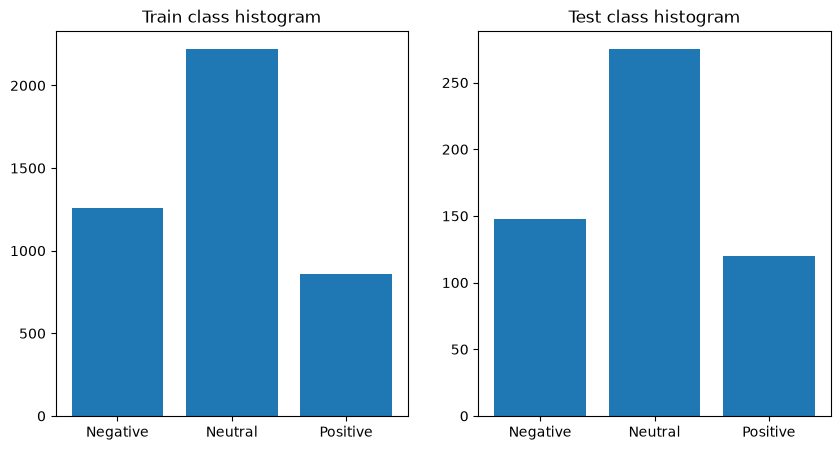

In [10]:
from matplotlib import pyplot as plt
from collections import Counter

fig, axs = plt.subplots(1, 2, figsize=(10, 5))

for ax, name in zip(axs, ["train", "test"]):
    counts = Counter(ds[name]["labels"])
    ax.bar(list(classes.values()), [counts[i] for i in classes])
    ax.set_title(f"{name.capitalize()} class histogram")

plt.show()

# 1. Custom model

In [11]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

SPECIAL_TOKENS = ["[PAD]", "[CLS]", "[UNK]"]

PAD = 0
CLS = 1
VOCAB_SIZE = 8000


def train_tokenizer(sequences: list[str], vocab_size: int) -> Tokenizer:
    tokenizer = Tokenizer(models.BPE(unk_token="[UNK]"))

    tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel()
    tokenizer.decoder = decoders.ByteLevel()

    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=SPECIAL_TOKENS,
        initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
        show_progress=False
    )

    tokenizer.train_from_iterator(sequences, trainer=trainer)
    return tokenizer

In [12]:
from tokenizers.processors import TemplateProcessing
from transformers import PreTrainedTokenizerFast

set_seed(SEED)

raw_tokenizer = train_tokenizer(ds["train"]["text"], VOCAB_SIZE)

raw_tokenizer.post_processor = TemplateProcessing(
    single="$A [CLS]",
    special_tokens=[("[CLS]", raw_tokenizer.token_to_id("[CLS]"))],
)

tokenizer_scratch = PreTrainedTokenizerFast(
    tokenizer_object=raw_tokenizer,
    pad_token="[PAD]",
    cls_token="[CLS]",
    unk_token="[UNK]",
    padding_side="right",
    model_input_names=["input_ids", "attention_mask"],
)

In [13]:
def tokenize(tokenizer, batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        max_length=128,
    )

In [14]:
from transformers import DataCollatorWithPadding

tokenized_scratch = ds.map(
    lambda x: tokenize(tokenizer_scratch, x),
    batched=True)

collator_scratch = DataCollatorWithPadding(tokenizer=tokenizer_scratch)

Now I check how long the sentences after tokenization are

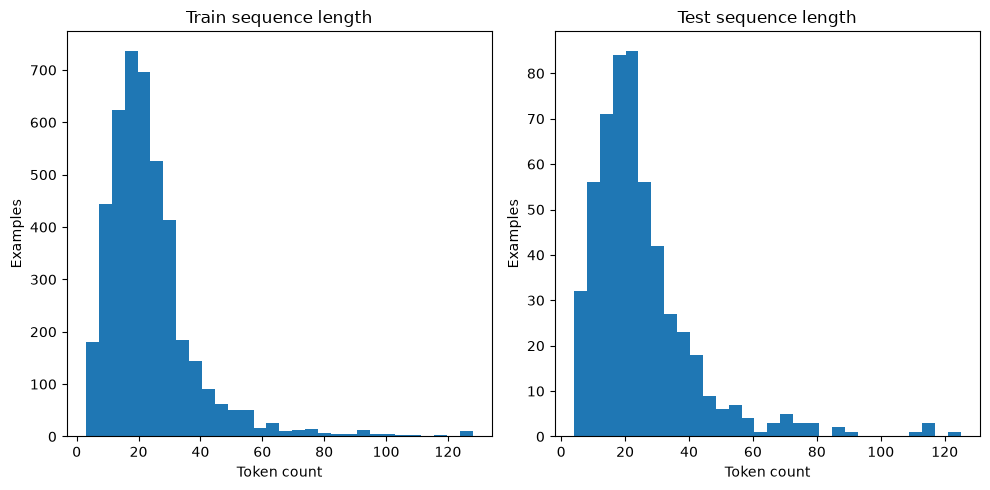

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(10, 5))

for ax, split, name in zip(
    axs,
    ["train", "test"],
    ["Train", "Test"],
):
    lengths = [len(ids) for ids in tokenized_scratch[split]["input_ids"]]

    ax.hist(lengths, bins=30)
    ax.set_title(f"{name} sequence length")
    ax.set_xlabel("Token count")
    ax.set_ylabel("Examples")

plt.tight_layout()
plt.show()

As a model trained from scratch I have implemented simple GPT architecture with classification head over the representation of the last token.

In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F


class MultiHeadAttention(nn.Module):
    def __init__(self, dim, num_heads):
        super().__init__()
        assert dim % num_heads == 0

        self.num_heads = num_heads
        self.head_dim = dim // num_heads

        self.qkv = nn.Linear(dim, 3 * dim, bias=False)
        self.proj = nn.Linear(dim, dim, bias=False)

    def forward(self, x):
        B, T, C = x.shape

        q, k, v = self.qkv(x).chunk(3, dim=-1)

        q = q.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.num_heads, self.head_dim).transpose(1, 2)

        out = F.scaled_dot_product_attention(
            q, k, v,
            is_causal=True
        )

        out = out.transpose(1, 2).contiguous().view(B, T, C)
        return self.proj(out)


class MLP(nn.Module):
    def __init__(self, dim, hidden_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(dim, hidden_dim),
            nn.GELU(),
            nn.Linear(hidden_dim, dim),
        )

    def forward(self, x):
        return self.net(x)


class TransformerBlock(nn.Module):
    def __init__(self, dim, num_heads, ff_hidden_dim, dropout):
        super().__init__()

        self.norm1 = nn.LayerNorm(dim)
        self.attn = MultiHeadAttention(dim, num_heads)

        self.norm2 = nn.LayerNorm(dim)
        self.mlp = MLP(dim, ff_hidden_dim)
        self.dropout = nn.Dropout(dropout)


    def forward(self, x):
        x = x + self.dropout(self.attn(self.norm1(x)))
        x = x + self.dropout(self.mlp(self.norm2(x)))
        return x


class SentimentClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        num_classes,
        dim,
        num_heads,
        ff_hidden_dim,
        num_layers,
        block_size,
        dropout=0.2,
    ):
        super().__init__()

        self.block_size = block_size

        self.token_embedding = nn.Embedding(vocab_size, dim)
        self.position_embedding = nn.Embedding(block_size, dim)

        self.blocks = nn.Sequential(*[
            TransformerBlock(dim, num_heads, ff_hidden_dim, dropout)
            for _ in range(num_layers)
        ])

        self.norm = nn.LayerNorm(dim)
        self.classifier = nn.Linear(dim, num_classes)

    def forward(self, input_ids, attention_mask=None, labels=None):
        B, T = input_ids.shape
        assert T <= self.block_size

        positions = torch.arange(T, device=input_ids.device)

        x = (
            self.token_embedding(input_ids)
            + self.position_embedding(positions)
        )

        x = self.blocks(x)
        x = self.norm(x)

        # last token has attended with whole sentence
        # so we chose his representation
        last = (input_ids != PAD).sum(dim=1) - 1
        x = x[torch.arange(B, device=input_ids.device), last]

        logits = self.classifier(x)
        output = {"logits": logits}

        if labels is not None:
            output["loss"] = F.cross_entropy(logits, labels)

        return output

In [17]:
BLOCK_SIZE = 128

model_scratch = SentimentClassifier(
    vocab_size=len(tokenizer_scratch),
    num_classes=3,
    dim=64,
    num_heads=2,
    ff_hidden_dim=32,
    num_layers=2,
    block_size=BLOCK_SIZE,
    dropout=0.2
)

params = sum(p.numel() for p in model_scratch.parameters())
print(f"Parameters: {params / 1_000_000:.1f}M")

Parameters: 0.6M


In [18]:
from sklearn.metrics import f1_score, accuracy_score
import numpy as np
from transformers import Trainer, TrainingArguments

BATCH_SIZE = 64
EPOCHS = 20
LR = 1e-4


def compute_metrics(pred):
    y_pred = np.argmax(pred.predictions, axis=-1)
    y_true = pred.label_ids

    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "f1": f1_score(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
    }

args_scratch = TrainingArguments(
    output_dir="./custom_sentiment",
    num_train_epochs=EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,
    learning_rate=LR,
    optim="adamw_torch",
    weight_decay=0.01,

    max_grad_norm=1.0,
    warmup_steps=0.05,
    lr_scheduler_type="constant_with_warmup",

    eval_strategy="epoch",
    logging_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,

    seed=SEED,
    report_to="none",
    disable_tqdm=False,
)

trainer_scratch = Trainer(
    model=model_scratch,
    args=args_scratch,
    train_dataset=tokenized_scratch["train"],
    eval_dataset=tokenized_scratch["validation"],
    processing_class=tokenizer_scratch,
    data_collator=collator_scratch,
    compute_metrics=compute_metrics,
)

train_result_scratch = trainer_scratch.train()
training_times["Scratch"] = {
    "training_total_s": train_result_scratch.metrics["train_runtime"],
    "epochs": trainer_scratch.state.epoch,
    "training_mean_epoch_s": (
        train_result_scratch.metrics["train_runtime"] / trainer_scratch.state.epoch
    ),
}
print("Best scratch checkpoint:", trainer_scratch.state.best_model_checkpoint)

Epoch,Training Loss,Validation Loss,Accuracy,F1
1,1.093252,1.062109,0.472325,0.317314
2,1.055953,1.043769,0.487085,0.313680
3,1.037826,1.030004,0.498155,0.316969
4,1.020674,1.017604,0.498155,0.323245
5,1.008851,1.006192,0.500000,0.338961
6,0.997182,0.999153,0.505535,0.317563
7,0.986695,0.991409,0.503690,0.334826
8,0.979245,0.987424,0.520295,0.352477
9,0.968252,0.986589,0.520295,0.338176
10,0.962176,0.980150,0.509225,0.341664


[transformers] mtime may not be reliable on this filesystem, falling back to numerical ordering


Best scratch checkpoint: ./custom_sentiment/checkpoint-1360


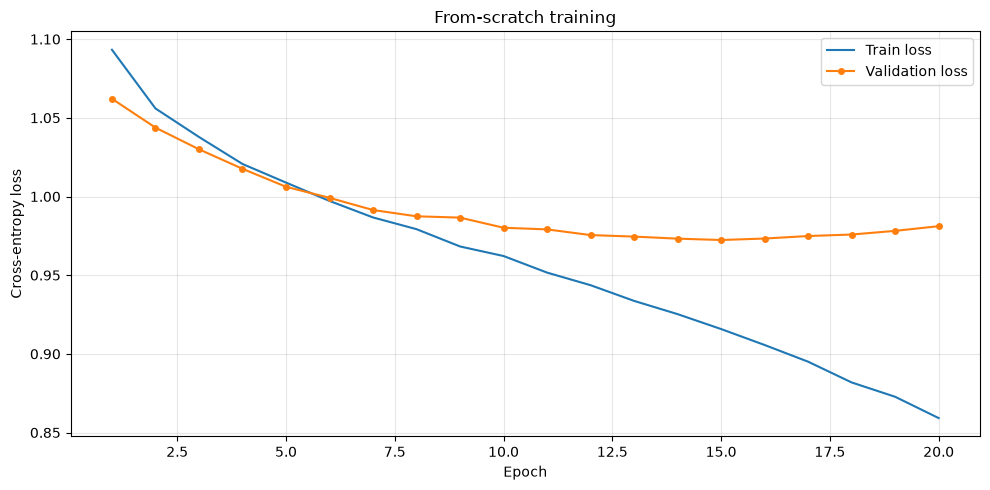

In [19]:
history_scratch = trainer_scratch.state.log_history
plot_training_history(history_scratch, "From-scratch training")


In [20]:
from datasets import Dataset
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

INFERENCE_BATCH_SIZE = 8


def test_model(trainer, data, batch_size=INFERENCE_BATCH_SIZE):
    trainer.args.per_device_eval_batch_size = batch_size
    model_device = trainer.args.device
    texts = list(data["text"])

    if model_device.type == "cuda":
        torch.cuda.synchronize(model_device)
    start = perf_counter()
    # Encode raw texts on every call; no cached tokenized dataset is used.
    encoded = tokenize(trainer.processing_class, {"text": texts})
    result = trainer.predict(Dataset.from_dict(encoded))
    if model_device.type == "cuda":
        torch.cuda.synchronize(model_device)
    inference_time = perf_counter() - start

    # Labels and quality metrics stay outside the encoding + inference timer.
    y_true = np.asarray(data["labels"])
    y_pred = result.predictions.argmax(axis=-1)
    loss = F.cross_entropy(
        torch.from_numpy(result.predictions).float(),
        torch.from_numpy(y_true).long(),
    ).item()

    metrics = {
        "loss": loss,
        "inference_time_seconds": inference_time,
        "inference_samples_per_second": len(data) / inference_time,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=[0, 1, 2],
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(
            y_true, y_pred, labels=[0, 1, 2]
        ),
    }

    print(f"Test loss:     {metrics['loss']:.4f}")
    print(f"Test accuracy: {metrics['accuracy']:.2%}")
    print(f"Test macro F1: {metrics['macro_f1']:.4f}")
    print(f"Test encoding + inference time: {metrics['inference_time_seconds']:.3f} s")
    print(f"Test throughput: {metrics['inference_samples_per_second']:.1f} examples/s")

    ConfusionMatrixDisplay(
        confusion_matrix=metrics["confusion_matrix"],
        display_labels=[classes[i] for i in [0, 1, 2]],
    ).plot(cmap="Blues", values_format="d")
    plt.tight_layout()
    plt.show()

    return metrics


Test loss:     0.9971
Test accuracy: 54.14%
Test macro F1: 0.4266
Test encoding + inference time: 0.117 s
Test throughput: 4625.3 examples/s


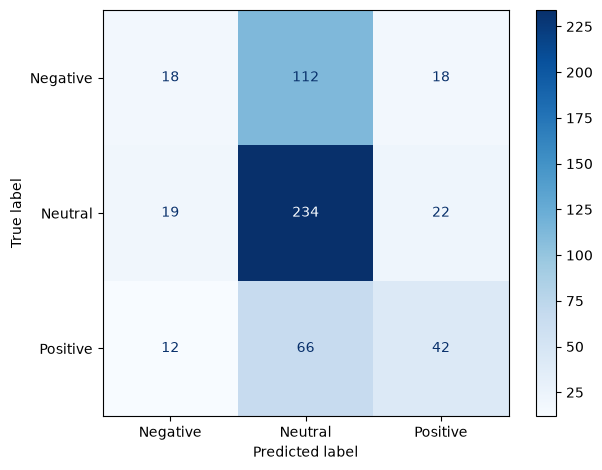

In [21]:
scratch_results = test_model(trainer_scratch, ds["test"])


In [22]:
del trainer_scratch, model_scratch
del collator_scratch, tokenized_scratch, tokenizer_scratch, raw_tokenizer
free_memory()

As we can see, training a model from scratch is rather hard with limited dataset size. The model overfits a lot and F1 of 45% on 3 classes is not great. On train/val plot we can observe that model doesn't generalize well and validation loss goes up - model starts to be more and more confident of wrong predictions.

# 2. Fine-tuning

In [23]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

set_seed(SEED)

MODEL_NAME = "speakleash/Bielik-1.5B-v3"
NUM_CLASSES = 3

tokenizer_pretrained = AutoTokenizer.from_pretrained(MODEL_NAME, token=hf_token)
tokenizer_pretrained.pad_token = tokenizer_pretrained.eos_token
tokenizer_pretrained.padding_side = "right"

model_pretrained = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_CLASSES,
    torch_dtype=torch.bfloat16,
)

model_pretrained.config.pad_token_id = tokenizer_pretrained.pad_token_id

print(f"Parameters: {model_pretrained.num_parameters() / 1_000_000_000:.1f}B")

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/514 [00:00<?, ?it/s]

[transformers] LlamaForSequenceClassification LOAD REPORT from: speakleash/Bielik-1.5B-v3
Key            | Status     | 
---------------+------------+-
lm_head.weight | UNEXPECTED | 
score.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Parameters: 1.5B


In [24]:
from peft import LoraConfig, TaskType, get_peft_model
lora_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    target_modules=["q_proj", "v_proj"],
    modules_to_save=["score"],
)

model_pretrained_lora = get_peft_model(model_pretrained, lora_config)
model_pretrained_lora.print_trainable_parameters()

trainable params: 1,249,792 || all params: 1,548,610,048 || trainable%: 0.0807


In [25]:
tokenized_pretrained = ds.map(lambda x: tokenize(tokenizer_pretrained, x), batched=True)

collator_pretrained = DataCollatorWithPadding(tokenizer=tokenizer_pretrained)

In [26]:
from transformers import Trainer, TrainingArguments

args_pretrained = TrainingArguments(
    output_dir="./bielik_sentiment",
    num_train_epochs=3,
    per_device_train_batch_size=4,
    per_device_eval_batch_size=4,
    gradient_accumulation_steps=4,
    learning_rate=2e-4,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    greater_is_better=True,
    logging_steps=50,
    seed=SEED,
    report_to="none",
)

trainer_pretrained = Trainer(
    model=model_pretrained_lora,
    args=args_pretrained,
    train_dataset=tokenized_pretrained["train"],
    eval_dataset=tokenized_pretrained["validation"],
    processing_class=tokenizer_pretrained,
    data_collator=collator_pretrained,
    compute_metrics=compute_metrics,
)

train_result_pretrained = trainer_pretrained.train()
training_times["Bielik + LoRA"] = {
    "training_total_s": train_result_pretrained.metrics["train_runtime"],
    "epochs": trainer_pretrained.state.epoch,
    "training_mean_epoch_s": (
        train_result_pretrained.metrics["train_runtime"] / trainer_pretrained.state.epoch
    ),
}

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 4}.


Epoch,Training Loss,Validation Loss,Accuracy,F1
1,2.916494,0.775311,0.649446,0.652271
2,2.446045,0.684925,0.686347,0.678172
3,2.028047,0.687556,0.695572,0.686490


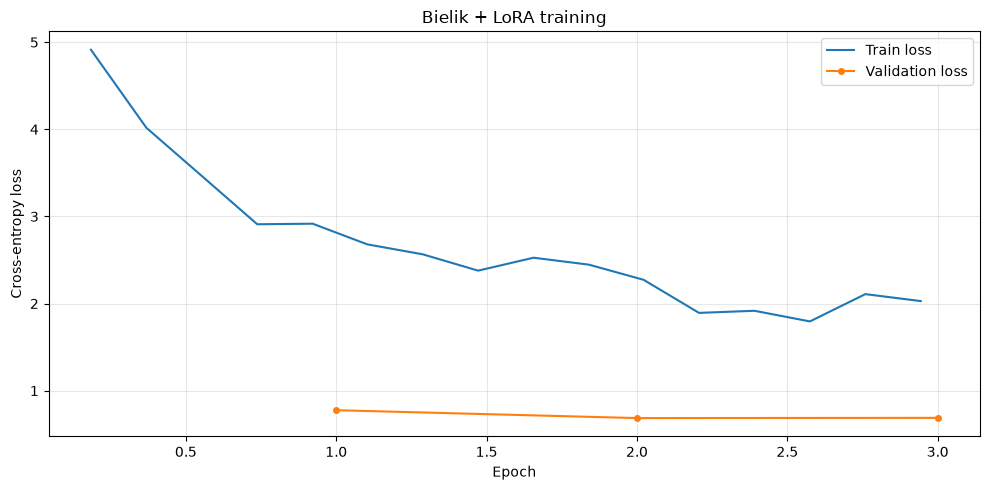

In [27]:
history_pretrained = trainer_pretrained.state.log_history
plot_training_history(history_pretrained, "Bielik + LoRA training")


Test loss:     0.7135
Test accuracy: 69.06%
Test macro F1: 0.6798
Test encoding + inference time: 6.034 s
Test throughput: 90.0 examples/s


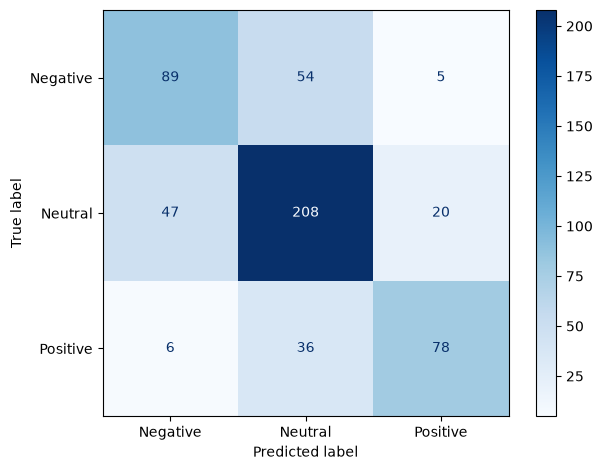

In [28]:
pretrained_results = test_model(trainer_pretrained, ds["test"])


Training runtime includes validation and checkpoint saving. Mean time per epoch is total runtime divided by the number of completed epochs.


In [29]:
training_time_summary = pd.DataFrame.from_dict(training_times, orient="index")
display(training_time_summary)


,training_total_s,epochs,training_mean_epoch_s
Scratch,10.9919,20.0,0.549595
Bielik + LoRA,351.1654,3.0,117.055133


In [30]:
del trainer_pretrained, model_pretrained_lora, model_pretrained
del collator_pretrained, tokenized_pretrained, tokenizer_pretrained
free_memory()

# 3. Zero-shot

In [31]:
from transformers import AutoModelForCausalLM

tokenizer_zero_shot = AutoTokenizer.from_pretrained(MODEL_NAME)
model_zero_shot = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

In [32]:
tokenizer_zero_shot.pad_token = tokenizer_zero_shot.eos_token
tokenizer_zero_shot.padding_side = "right"
model_zero_shot.config.pad_token_id = tokenizer_zero_shot.pad_token_id


In [33]:
POSITIVE_TOKEN="pozytywny"
NEUTRAL_TOKEN="neutralny"
NEGATIVE_TOKEN="negatywny"

classes_pl = {
    0: NEGATIVE_TOKEN,
    1: NEUTRAL_TOKEN,
    2: POSITIVE_TOKEN
}

In [34]:
class_token_ids = {
    tokenizer_zero_shot.encode(v, add_special_tokens=False)[0]: k
    for k, v in classes_pl.items()
}

In [35]:
zero_shot_prompt = f"""
Określ sentyment poniższego tekstu.
Możliwe odpowiedzi: {NEGATIVE_TOKEN}, {NEUTRAL_TOKEN}, {POSITIVE_TOKEN}.

Tekst: {{text}}
Sentyment:
""".strip()

In [36]:
from tqdm import tqdm


@torch.inference_mode()
def predict_zero_shot_logits(model, tokenizer, texts, batch_size=INFERENCE_BATCH_SIZE):
    model.eval()
    token_ids = sorted(class_token_ids, key=class_token_ids.get)
    all_logits = []

    for start in tqdm(range(0, len(texts), batch_size), desc="Zero-shot"):
        batch = texts[start:start + batch_size]
        prompts = [zero_shot_prompt.format(text=text) for text in batch]
        inputs = tokenizer(prompts, padding=True, return_tensors="pt").to(model.device)

        outputs = model(**inputs, use_cache=False)
        last_positions = inputs["attention_mask"].sum(dim=1) - 1
        rows = torch.arange(len(batch), device=model.device)
        # Keep only the next-token logits for our three class indicators.
        class_logits = outputs.logits[rows, last_positions][:, token_ids]
        all_logits.append(class_logits.float().cpu())
        del outputs

    return torch.cat(all_logits)


def predict_zero_shot(model, tokenizer, texts, batch_size=INFERENCE_BATCH_SIZE):
    class_logits = predict_zero_shot_logits(model, tokenizer, texts, batch_size)
    # Normalize over the selected class tokens only, in class ID order.
    # T = 1: no temperature calibration is applied to Bielik.
    probabilities = torch.softmax(class_logits, dim=-1).numpy()
    class_ids = np.asarray(sorted(class_token_ids.values()))
    predictions = class_ids[probabilities.argmax(axis=-1)]
    return predictions, probabilities


In [37]:
def test_zero_shot(model, tokenizer, data, batch_size=INFERENCE_BATCH_SIZE):
    texts = list(data["text"])
    if model.device.type == "cuda":
        torch.cuda.synchronize(model.device)
    start = perf_counter()
    y_pred, probabilities = predict_zero_shot(model, tokenizer, texts, batch_size=batch_size)
    if model.device.type == "cuda":
        torch.cuda.synchronize(model.device)
    inference_time = perf_counter() - start
    y_true = np.asarray(data["labels"])
    labels = list(classes)

    metrics = {
        "inference_time_seconds": inference_time,
        "inference_samples_per_second": len(data) / inference_time,
        "probabilities": probabilities,
        "probability_class_ids": sorted(class_token_ids.values()),
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=labels,
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(y_true, y_pred, labels=labels),
        "predictions": y_pred,
        "predicted_classes": [classes[label] for label in y_pred],
    }

    print(f"Test accuracy: {metrics['accuracy']:.2%}")
    print(f"Test macro F1: {metrics['macro_f1']:.4f}")
    print(f"Test encoding + inference time: {metrics['inference_time_seconds']:.3f} s")
    print(f"Test throughput: {metrics['inference_samples_per_second']:.1f} examples/s")

    ConfusionMatrixDisplay(
        confusion_matrix=metrics["confusion_matrix"],
        display_labels=[classes[label] for label in labels],
    ).plot(cmap="Blues", values_format="d")
    plt.tight_layout()
    plt.show()

    return metrics


Zero-shot: 100%|██████████| 68/68 [00:08<00:00,  7.92it/s]

Test accuracy: 62.98%
Test macro F1: 0.5911
Test encoding + inference time: 8.586 s
Test throughput: 63.2 examples/s


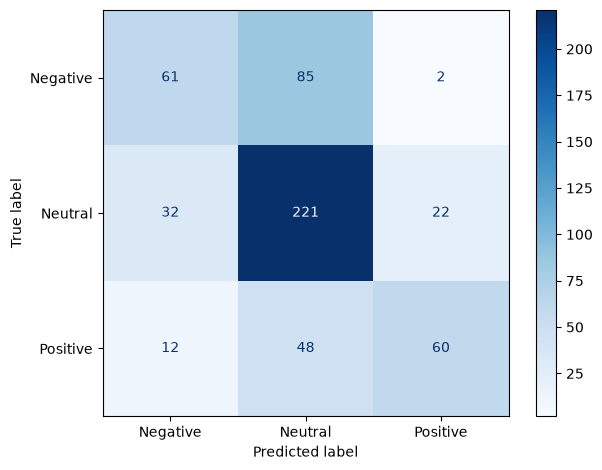

In [38]:
zero_shot_results = test_zero_shot(
    model_zero_shot,
    tokenizer_zero_shot,
    ds["test"],
    batch_size=INFERENCE_BATCH_SIZE,
)


In [39]:
probability_examples = pd.DataFrame(
    zero_shot_results["probabilities"][:6],
    columns=[classes[label] for label in zero_shot_results["probability_class_ids"]],
)
probability_examples.insert(0, "Text", list(ds["test"]["text"][:6]))
probability_examples.insert(1, "True class", [classes[label] for label in ds["test"]["labels"][:6]])
probability_examples.insert(2, "Predicted class", zero_shot_results["predicted_classes"][:6])
with pd.option_context("display.max_colwidth", None):
    display(probability_examples.round(4))


,Text,True class,Predicted class,Negative,Neutral,Positive
0,"-Wiedziałeś o tym, że Chopin odkrył poruszanie się słońca wokół Ziemii? -Co to za sritititi.",Negative,Neutral,0.1662,0.7448,0.0890
1,- masz malego - twój stary,Negative,Neutral,0.1644,0.6109,0.2247
2,"- Jesteś Sigma ? - Nie, jestem Ypsilon.",Neutral,Neutral,0.1372,0.7417,0.1211
3,"- Mordo ale śmierdzisz -Ta, właśnie idę zwodować jajo",Neutral,Neutral,0.2742,0.5123,0.2135
4,"Ludzie którzy nie rozumieją contentu Marcel to albo debile, albo boomerzy.",Negative,Negative,0.3599,0.3599,0.2803
5,"U mnie w podstawówce to palarnia była dosłownie przy drugim wejściu do szkoły, nauczyciele widzieli, nic sobie z tego nie robili (patola straszna).",Negative,Negative,0.4321,0.3366,0.2313


In [40]:
del model_zero_shot, tokenizer_zero_shot
free_memory()


In [41]:
comparison = pd.DataFrame([
    {
        "Model": name,
        "accuracy": results["accuracy"],
        "macro_f1": results["macro_f1"],
        "training_total_s": training_times[name]["training_total_s"] if name != "Bielik zero-shot" else 0.0,
        "training_mean_epoch_s": training_times[name]["training_mean_epoch_s"] if name != "Bielik zero-shot" else np.nan,
        "encoding_inference_total_s": results["inference_time_seconds"],
        "encoding_inference_examples_per_second": results["inference_samples_per_second"],
    }
    for name, results in [
        ("Scratch", scratch_results),
        ("Bielik + LoRA", pretrained_results),
        ("Bielik zero-shot", zero_shot_results),
    ]
]).set_index("Model")
display(comparison)


,accuracy,macro_f1,training_total_s,training_mean_epoch_s,encoding_inference_total_s,encoding_inference_examples_per_second
Model,,,,,,
Scratch,0.541436,0.426602,10.9919,0.549595,0.117398,4625.293516
Bielik + LoRA,0.690608,0.679783,351.1654,117.055133,6.033791,89.993168
Bielik zero-shot,0.629834,0.591050,0.0000,NaN,8.586447,63.239194


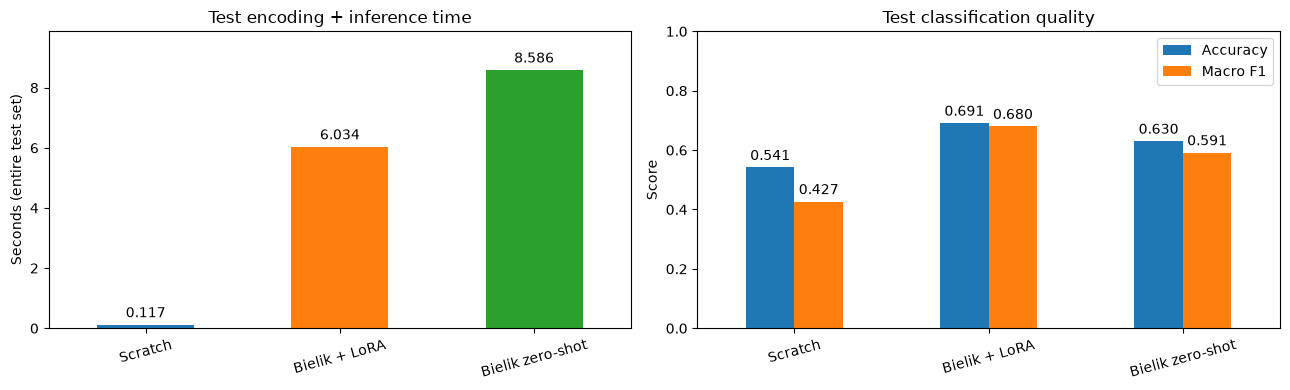

In [42]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))

comparison["encoding_inference_total_s"].plot.bar(
    ax=axs[0], rot=15, color=["tab:blue", "tab:orange", "tab:green"],
)
axs[0].set_title("Test encoding + inference time")
axs[0].set_ylabel("Seconds (entire test set)")
axs[0].set_xlabel("")
axs[0].bar_label(axs[0].containers[0], fmt="%.3f", padding=3)
axs[0].margins(y=0.15)

comparison[["accuracy", "macro_f1"]].plot.bar(ax=axs[1], rot=15)
axs[1].set_title("Test classification quality")
axs[1].set_ylabel("Score")
axs[1].set_xlabel("")
axs[1].set_ylim(0, 1)
axs[1].legend(["Accuracy", "Macro F1"])
for bars in axs[1].containers:
    axs[1].bar_label(bars, fmt="%.3f", padding=3)

plt.tight_layout()
plt.show()
